# Lab 3 - Building a complete AI risk strategy

**Scenario.** SmartHire is a fictional CV-screening tool. It has a gender-related ranking gap, limited explainability, and no logging or monitoring.

**Objective.** Produce a strategy structured across four domains, export it to YAML, and verify that the documentation and visualisation are created.

## How to use this notebook

A risk strategy is not a static list: it connects a scenario, controls, owners, and evidence. This notebook shows how to structure and share that list. Run cells in order: the strategy is defined, validated, exported, reloaded, and then visualised. **Test** cells confirm that each step produced its expected result.

In [1]:
from pathlib import Path
from datetime import date
import yaml
import matplotlib.pyplot as plt

PROJECT_ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / "requirements.txt").exists()), Path.cwd())
ARTIFACTS = PROJECT_ROOT / "notebooks_en" / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)

## 1. Define the scope and controls

Controls are organised by domain so that AI risk is not reduced to a purely technical issue. This list is a starting point: every control needs an owner, date, acceptance criterion, and evidence.

**Reading the structure:** the dictionary uses a domain as its key and a control list as its value. `Technique` covers model behaviour; `Opérationnel` covers how the system runs over time; `Éthique` covers effects on people; and `Juridique` covers applicable obligations. The final loop prints the items before export. The test requires four domains and at least three non-empty controls in each: this is a minimum completeness check.

In [2]:
risk_strategy = {
    "Technical": ["Measure fairness gaps before every release", "Monitor drift and performance after deployment", "Provide understandable ranking reasons"],
    "Operational": ["Version the model, data, and parameters", "Maintain data lineage and change tracking", "Test an AI incident-response plan"],
    "Ethical": ["Audit bias across relevant populations", "Define fairness criteria with stakeholders", "Provide human review and an appeal route"],
    "Legal": ["Document the legal basis and applicable consent", "Assess automated decisions with significant effects", "Validate transparency and non-discrimination obligations"],
}
for domain, controls in risk_strategy.items():
    print(f"\n{domain.upper()} ({len(controls)} controls)")
    for control in controls:
        print(f"- {control}")


TECHNICAL (3 controls)
- Measure fairness gaps before every release
- Monitor drift and performance after deployment
- Provide understandable ranking reasons

OPERATIONAL (3 controls)
- Version the model, data, and parameters
- Maintain data lineage and change tracking
- Test an AI incident-response plan

ETHICAL (3 controls)
- Audit bias across relevant populations
- Define fairness criteria with stakeholders
- Provide human review and an appeal route

LEGAL (3 controls)
- Document the legal basis and applicable consent
- Assess automated decisions with significant effects
- Validate transparency and non-discrimination obligations


In [3]:
# Test - balanced strategy: four domains and three non-empty controls in each.
assert set(risk_strategy) == {"Technical", "Operational", "Ethical", "Legal"}
assert all(len(controls) >= 3 and all(isinstance(c, str) and c for c in controls) for controls in risk_strategy.values())
print("OK - structured, complete strategy.")

OK - structured, complete strategy.


## 2. Export readable YAML documentation

YAML is readable by people and usable by software. `safe_dump` prevents Python-specific types from being emitted; `allow_unicode=True` preserves French accents. Reloading after writing is critical: it verifies the delivered artefact, not only the in-memory object.

**Flow:** `document` separates metadata from the business strategy; `safe_dump` converts the dictionary to YAML; `write_text` saves the file; and the Test cell uses `safe_load` to reload it and compare the reloaded strategy with the original. If they differ, execution stops, exposing a serialisation or path problem.

In [4]:
document = {
    "metadata": {
        "project": "SmartHire - AI risk strategy",
        "date_generation": date.today().isoformat(),
        "status": "Draft pending validation",
        "scenario": "Ranking gap, insufficient explainability, and no monitoring.",
    },
    "risk_strategy": risk_strategy,
}
yaml_path = ARTIFACTS / "lab3_risk_strategy.yaml"
yaml_path.write_text(yaml.safe_dump(document, allow_unicode=True, sort_keys=False), encoding="utf-8")
print(yaml_path.read_text(encoding="utf-8"))

metadata:
  project: SmartHire - AI risk strategy
  date_generation: '2026-11-02'
  status: Draft pending validation
  scenario: Ranking gap, insufficient explainability, and no monitoring.
risk_strategy:
  Technical:
  - Measure fairness gaps before every release
  - Monitor drift and performance after deployment
  - Provide understandable ranking reasons
  Operational:
  - Version the model, data, and parameters
  - Maintain data lineage and change tracking
  - Test an AI incident-response plan
  Ethical:
  - Audit bias across relevant populations
  - Define fairness criteria with stakeholders
  - Provide human review and an appeal route
  Legal:
  - Document the legal basis and applicable consent
  - Assess automated decisions with significant effects
  - Validate transparency and non-discrimination obligations



In [5]:
# Test - YAML reload and business-content equality.
loaded = yaml.safe_load(yaml_path.read_text(encoding="utf-8"))
assert loaded["risk_strategy"] == risk_strategy
assert loaded["metadata"]["project"].startswith("SmartHire")
assert yaml_path.exists()
print("OK - YAML export reloaded and validated.")

OK - YAML export reloaded and validated.


## 3. Visualise control coverage

The chart counts controls; it does not measure their effectiveness. A domain with more controls is not necessarily better covered: evidence quality and observed effectiveness remain decisive.

**How the chart is made:** `domains` preserves the domain order, `counts` calculates the length of each list, `bar` draws one bar per domain, and the loop places the count above each bar. `savefig` creates an image that can be reused in a report. The test compares displayed counts with the source lists and confirms the image exists and is non-empty. Interpret differences afterwards: a small number may signal a gap or simply broader controls, so effectiveness must be examined.

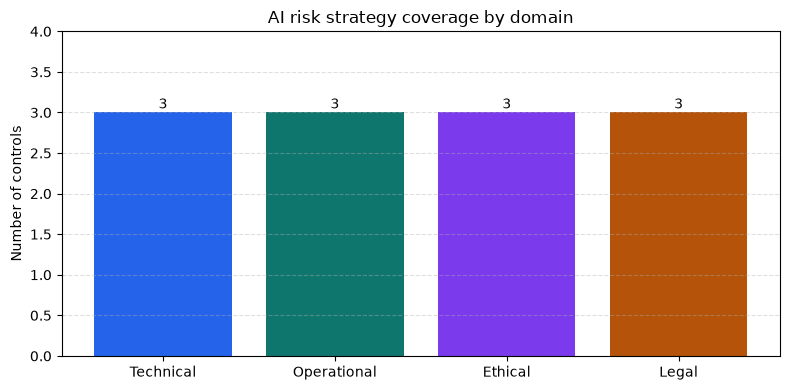

In [6]:
domains = list(risk_strategy)
counts = [len(risk_strategy[d]) for d in domains]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(domains, counts, color=["#2563eb", "#0f766e", "#7c3aed", "#b45309"])
ax.set_title("AI risk strategy coverage by domain")
ax.set_ylabel("Number of controls")
ax.set_ylim(0, max(counts) + 1)
ax.grid(axis="y", linestyle="--", alpha=.4)
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, count + .05, str(count), ha="center")
fig.tight_layout()
figure_path = ARTIFACTS / "lab3_couverture_controls.png"
fig.savefig(figure_path, dpi=150)
plt.show()

In [7]:
# Test - counts match the strategy and the image was written.
assert counts == [len(v) for v in risk_strategy.values()]
assert figure_path.exists() and figure_path.stat().st_size > 1_000
print("OK - visualisation created and validated.")

OK - visualisation created and validated.


## Final reflection

What evidence would you request to judge whether a control is effective? Consider metrics, logs, human reviews, and candidate feedback. A strategy becomes operational only when its controls are measured, followed up, and improved over time.